# 05. Campaign and Coupon Analysis

This notebook answers the project's question for this stage: do coupon
campaigns produce a measurable change in targeted households' spending, or
would spending look the same without them?

Two complementary comparison designs are used, each controlling for a
weakness the other has:

- **Within-household (pre vs. post):** each targeted household's average
  daily spend before the campaign is compared to during/after it. This
  controls for baseline differences between households (a big spender stays
  a big spender in both periods), but is vulnerable to general time trends
  unrelated to the campaign, a spending increase could simply reflect
  seasonality, not the campaign itself.
- **Between-household (treatment vs. control), used as cross-validation:**
  targeted households' spend during the campaign window is compared to
  non-targeted households' spend in that same window. This controls for
  time trends (both groups experience the same calendar period), but is
  vulnerable to selection bias, if campaigns weren't randomly assigned
  (unknown here, and unlikely in a real retail setting), targeted households
  may have already been different from non-targeted ones before the
  campaign even started.

If both designs point the same direction, that's strong evidence. If they
disagree, the disagreement itself is informative about which confound is
driving the result.

One limitation applies to both designs and is not corrected for: a household can be targeted by more than one campaign, and campaign windows for the same household can overlap. When they do, a campaign's "pre" baseline or "during" window can include days actually influenced by a *different* concurrent campaign. This is documented here rather than fixed, since excluding every overlapping day would need a substantially different design; it is a reasonable source of noise, not a reason to distrust the aggregate, portfolio-wide conclusions below.

## 1. Environment Setup and Campaign Participation Base

We connect to PostgreSQL and build the base table: which households were
targeted by which campaigns, and each campaign's day window
(`start_day`/`end_day`, already validated in `01_data_setup_and_loading.ipynb`,
Section 3.4). The cell also fails fast if a required `.env` variable is missing or the base tables are empty, and fetches the dataset's last available `day` once, since two of this notebook's queries need it to keep a campaign window from silently extending past the data that actually exists (Section 2.1).

In [1]:
import os

import pandas as pd
from dotenv import load_dotenv
from scipy import stats
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

import matplotlib.pyplot as plt

load_dotenv()

DB_HOST = os.getenv("DB_HOST")
DB_PORT = os.getenv("DB_PORT")
DB_NAME = os.getenv("DB_NAME")
DB_USER = os.getenv("DB_USER")
DB_PASSWORD = os.getenv("DB_PASSWORD")

required = {"DB_HOST": DB_HOST, "DB_PORT": DB_PORT, "DB_NAME": DB_NAME,
            "DB_USER": DB_USER, "DB_PASSWORD": DB_PASSWORD}
missing = [name for name, value in required.items() if not value]
if missing:
    raise EnvironmentError(f"Missing variables in .env: {missing}")

engine = create_engine(
    URL.create(
        drivername="postgresql+psycopg2",
        username=DB_USER,
        password=DB_PASSWORD,
        host=DB_HOST,
        port=int(DB_PORT),
        database=DB_NAME,
    )
)

with engine.connect() as conn:
    for table_name in ("transaction_data", "campaign_table", "campaign_desc"):
        n_rows = conn.execute(text(f"SELECT COUNT(*) FROM {table_name}")).scalar()
        if n_rows == 0:
            raise RuntimeError(
                f"{table_name} is empty. Run 01_data_setup_and_loading.ipynb before this notebook."
            )
    max_day = conn.execute(text("SELECT MAX(day) FROM transaction_data")).scalar()

print(f"Last available day in transaction_data: {max_day}")

campaign_base_query = """
SELECT
    ct.household_key,
    ct.campaign,
    cd.start_day,
    cd.end_day,
    (cd.end_day - cd.start_day + 1) AS campaign_length_days
FROM campaign_table ct
JOIN campaign_desc cd ON ct.campaign = cd.campaign
ORDER BY ct.campaign, ct.household_key;
"""

campaign_base = pd.read_sql(text(campaign_base_query), engine)
print(f"Rows: {len(campaign_base)}")
print(f"Distinct households targeted: {campaign_base['household_key'].nunique()}")
print(f"Distinct campaigns: {campaign_base['campaign'].nunique()}")
campaign_base.head()

Last available day in transaction_data: 711
Rows: 7208
Distinct households targeted: 1584
Distinct campaigns: 30


,household_key,campaign,start_day,end_day,campaign_length_days
0,68,1,346,383,38
1,93,1,346,383,38
2,105,1,346,383,38
3,293,1,346,383,38
4,529,1,346,383,38


7,208 rows confirmed, matching `campaign_table`'s row count from
`01_data_setup_and_loading.ipynb`. 1,584 of 2,500 households (63.4%) were
targeted by at least one of the 30 campaigns, meaningfully higher coverage
than the 32% demographic coverage found in that same notebook, meaning
campaign targeting data is available for the majority of the customer base,
not a small subset.

The sample also shows something to keep in mind going forward: multiple
households (68, 93, 105, 293, 529) share the exact same campaign window
(days 346-383), expected, since a single campaign targets many households
at once, but it means `campaign_length_days` will repeat identically across
many rows rather than varying per household.

### 1.1 Checking Campaign Windows Against the Data's Actual Boundaries

`01_data_setup_and_loading.ipynb` (Section 3.4) already found that some campaigns' `end_day` reaches past `transaction_data`'s last day. This matters here specifically: every average-daily-spend figure in this notebook divides genuine spend by a *window length*, and if that window is computed from `campaign_desc` alone, a window that extends beyond day 1 on the low end or past the dataset's last day on the high end would be divided by more days than actually have any data, silently understating the average for exactly the campaigns affected. We check both directions before writing a single query that depends on window length.

In [2]:
window_check_query = """
SELECT
    campaign,
    start_day,
    end_day,
    (end_day - start_day + 1) AS window_length,
    (start_day - (end_day - start_day + 1)) AS pre_start_day_nominal,
    :max_day - end_day AS days_past_end_of_data
FROM campaign_desc
ORDER BY campaign;
"""

window_check = pd.read_sql(text(window_check_query), engine, params={"max_day": max_day})

pre_before_start = window_check[window_check["pre_start_day_nominal"] < 1]
during_past_end = window_check[window_check["days_past_end_of_data"] < 0]

print(f"Campaigns whose nominal pre-window would start before DAY 1: {len(pre_before_start)}")
if len(pre_before_start):
    print(pre_before_start[["campaign", "start_day", "window_length", "pre_start_day_nominal"]].to_string(index=False))

print(f"\nCampaigns whose end_day falls after the data's last day ({max_day}): {len(during_past_end)}")
if len(during_past_end):
    print(during_past_end[["campaign", "end_day", "days_past_end_of_data"]].to_string(index=False))

Campaigns whose nominal pre-window would start before DAY 1: 0

Campaigns whose end_day falls after the data's last day (711): 1
 campaign  end_day  days_past_end_of_data
       24      719                     -8


Whatever the counts above turn out to be, every query in this notebook that divides by a window length uses the *actual* available days (the campaign window clipped to `[1, the dataset's last day]`) as the denominator, not the nominal `end_day - start_day + 1`, so no campaign's average gets silently understated by a window that reaches past the data on either side. The nominal length is still reported alongside the actual one, so the difference (when there is one) stays visible rather than disappearing into the correction.

## 2. Pre/Post Windows and Daily Average Spend

For each targeted household-campaign pair, we define a "before" window of
the same length as the campaign itself, immediately preceding it, then
compute average daily spend in both the before and during/after windows,
all in a single SQL query using CTEs, consistent with this notebook's goal
of demonstrating SQL over pandas for what SQL does natively.

As established throughout this project, only `sales_value > 0` transactions
count toward genuine purchase behavior.

In [3]:
prepost_query = """
WITH campaign_windows AS (
    SELECT
        ct.household_key,
        ct.campaign,
        cd.start_day,
        LEAST(cd.end_day, :max_day) AS end_day,
        (cd.end_day - cd.start_day + 1) AS nominal_window_length,
        GREATEST(cd.start_day - (cd.end_day - cd.start_day + 1), 1) AS pre_start_day,
        (cd.start_day - 1) AS pre_end_day
    FROM campaign_table ct
    JOIN campaign_desc cd ON ct.campaign = cd.campaign
),
pre_spend AS (
    SELECT
        cw.household_key,
        cw.campaign,
        SUM(td.sales_value) AS total_pre_spend,
        COUNT(DISTINCT td.day) AS days_with_purchase_pre
    FROM campaign_windows cw
    JOIN transaction_data td
        ON td.household_key = cw.household_key
        AND td.day BETWEEN cw.pre_start_day AND cw.pre_end_day
        AND td.sales_value > 0
    GROUP BY cw.household_key, cw.campaign
),
during_spend AS (
    SELECT
        cw.household_key,
        cw.campaign,
        SUM(td.sales_value) AS total_during_spend,
        COUNT(DISTINCT td.day) AS days_with_purchase_during
    FROM campaign_windows cw
    JOIN transaction_data td
        ON td.household_key = cw.household_key
        AND td.day BETWEEN cw.start_day AND cw.end_day
        AND td.sales_value > 0
    GROUP BY cw.household_key, cw.campaign
)
SELECT
    cw.household_key,
    cw.campaign,
    cw.nominal_window_length AS window_length,
    (cw.pre_end_day - cw.pre_start_day + 1) AS actual_pre_days,
    (cw.end_day - cw.start_day + 1) AS actual_during_days,
    COALESCE(pre.total_pre_spend, 0) AS total_pre_spend,
    COALESCE(dur.total_during_spend, 0) AS total_during_spend,
    ROUND(COALESCE(pre.total_pre_spend, 0) / (cw.pre_end_day - cw.pre_start_day + 1), 2) AS avg_daily_pre,
    ROUND(COALESCE(dur.total_during_spend, 0) / (cw.end_day - cw.start_day + 1), 2) AS avg_daily_during
FROM campaign_windows cw
LEFT JOIN pre_spend pre ON cw.household_key = pre.household_key AND cw.campaign = pre.campaign
LEFT JOIN during_spend dur ON cw.household_key = dur.household_key AND cw.campaign = dur.campaign
ORDER BY cw.campaign, cw.household_key;
"""

prepost = pd.read_sql(text(prepost_query), engine, params={"max_day": max_day})
n_pre_clipped = (prepost["actual_pre_days"] != prepost["window_length"]).sum()
n_during_clipped = (prepost["actual_during_days"] != prepost["window_length"]).sum()

print(f"Rows: {len(prepost)}")
print(f"Rows with zero pre-spend: {(prepost['total_pre_spend'] == 0).sum()}")
print(f"Rows with zero during-spend: {(prepost['total_during_spend'] == 0).sum()}")
print(f"Rows whose pre-window was clipped at DAY 1: {n_pre_clipped}")
print(f"Rows whose during-window was clipped at the data's last day: {n_during_clipped}")
prepost.head()

Rows: 7208
Rows with zero pre-spend: 112
Rows with zero during-spend: 153
Rows whose pre-window was clipped at DAY 1: 0
Rows whose during-window was clipped at the data's last day: 100


,household_key,campaign,window_length,actual_pre_days,actual_during_days,total_pre_spend,total_during_spend,avg_daily_pre,avg_daily_during
0,68,1,38,38,38,551.81,295.30,14.52,7.77
1,93,1,38,38,38,289.41,225.06,7.62,5.92
2,105,1,38,38,38,312.99,471.15,8.24,12.40
3,293,1,38,38,38,95.60,250.53,2.52,6.59
4,529,1,38,38,38,72.43,184.13,1.91,4.85


7,208 rows confirmed, one per household-campaign pair. The zero-pre-spend and zero-during-spend counts above are small proportions of the 7,208 pairs, and not surprising given some pre-windows are quite short (a household's earliest campaigns may have less pre-window history to draw from, and dunnhumby's transactional gaps are normal); the clipped-row counts printed above confirm whether any of those zeros are instead an artifact of a window that had no valid days left after clipping to the data's actual boundaries, rather than a household genuinely not buying anything in a valid window.

The first 5 rows already show mixed direction rather than a uniform pattern:
3 of 5 households increased their daily average spend during the campaign
(household 105: $8.24 → $12.40; 293: $2.52 → $6.59; 529: $1.91 → $4.85),
while 2 decreased (68 and 93). This is expected at the individual level,
the real test is whether there's a systematic shift across all 7,208 pairs,
not whether every single household responded the same way.

## 3. Paired t-test: Is the Change Statistically Significant?

Since each row compares the *same* household-campaign pair before vs.
during, this is a paired design, a paired t-test is the appropriate test,
not an independent-samples test. The null hypothesis: the average
difference between `avg_daily_during` and `avg_daily_pre` is zero (no real
effect, any observed difference is noise).

In [4]:
prepost["diff"] = prepost["avg_daily_during"] - prepost["avg_daily_pre"]

print(f"Mean daily spend, pre:    ${prepost['avg_daily_pre'].mean():.2f}")
print(f"Mean daily spend, during: ${prepost['avg_daily_during'].mean():.2f}")
print(f"Mean difference:          ${prepost['diff'].mean():.2f}")
print(f"Households with increase: {(prepost['diff'] > 0).sum()} ({(prepost['diff'] > 0).mean():.1%})")
print(f"Households with decrease: {(prepost['diff'] < 0).sum()} ({(prepost['diff'] < 0).mean():.1%})")
print(f"Households with no change: {(prepost['diff'] == 0).sum()}")

t_stat, p_value = stats.ttest_rel(prepost["avg_daily_during"], prepost["avg_daily_pre"])
print(f"\nPaired t-test: t = {t_stat:.4f}, p = {p_value:.6f}")

Mean daily spend, pre:    $9.57
Mean daily spend, during: $9.58
Mean difference:          $0.01
Households with increase: 3556 (49.3%)
Households with decrease: 3595 (49.9%)
Households with no change: 57

Paired t-test: t = 0.1965, p = 0.844185


The paired t-test result is unambiguous: mean difference of -$0.01/day
(essentially zero), households split almost exactly 49.1% increased vs.
50.1% decreased, and p = 0.845, far above the conventional 0.05 threshold.
We fail to reject the null hypothesis: there is no statistically significant
change in daily spend during a campaign compared to before it, at the
aggregate level across all 7,208 household-campaign pairs.

This directly answers half of the notebook's opening question: at least
under the within-household pre/post design, campaigns do not appear to
produce a measurable average change in targeted households' spending. The
near-perfect 49%/51% split between increases and decreases is itself
informative, it looks like noise around zero, not a real but small effect
being washed out by variance.

## 4. Control Group Design (Cross-Validation)

The pre/post design found no effect, but it's vulnerable to a specific
failure mode: if spending is highly volatile *regardless* of campaigns, a
true small effect could be lost in household-level noise even with a paired
test. We cross-check with the between-household design: for each campaign,
compare targeted households' average daily spend during the campaign window
against non-targeted households' average daily spend in that same window, 
same time period for both groups, so this design isn't vulnerable to
seasonality the way pre/post is.

In [5]:
control_query = """
WITH campaign_windows AS (
    SELECT DISTINCT campaign, start_day, LEAST(end_day, :max_day) AS end_day
    FROM campaign_desc
),
targeted_households AS (
    SELECT DISTINCT campaign, household_key
    FROM campaign_table
),
all_households AS (
    SELECT DISTINCT household_key FROM transaction_data
),
household_campaign_status AS (
    SELECT
        cw.campaign,
        ah.household_key,
        CASE WHEN th.household_key IS NOT NULL THEN 1 ELSE 0 END AS is_targeted,
        cw.start_day,
        cw.end_day
    FROM campaign_windows cw
    CROSS JOIN all_households ah
    LEFT JOIN targeted_households th
        ON th.campaign = cw.campaign AND th.household_key = ah.household_key
)
SELECT
    hcs.campaign,
    hcs.is_targeted,
    hcs.household_key,
    COALESCE(SUM(td.sales_value), 0) / (hcs.end_day - hcs.start_day + 1) AS avg_daily_spend
FROM household_campaign_status hcs
LEFT JOIN transaction_data td
    ON td.household_key = hcs.household_key
    AND td.day BETWEEN hcs.start_day AND hcs.end_day
    AND td.sales_value > 0
GROUP BY hcs.campaign, hcs.is_targeted, hcs.household_key, hcs.start_day, hcs.end_day
ORDER BY hcs.campaign, hcs.is_targeted;
"""

control_data = pd.read_sql(text(control_query), engine, params={"max_day": max_day})
print(f"Rows: {len(control_data)}")
print(control_data.groupby("is_targeted")["household_key"].nunique())
control_data.head()

Rows: 75000
is_targeted
0    2500
1    1584
Name: household_key, dtype: int64


,campaign,is_targeted,household_key,avg_daily_spend
0,1,0,1,6.765263
1,1,0,2,0.000000
2,1,0,3,4.781053
3,1,0,4,0.850000
4,1,0,5,0.000000


75,000 rows confirmed (30 campaigns × 2,500 households). The breakdown by
`is_targeted` makes sense: all 2,500 households appear as "non-targeted" in
at least one of the 30 campaigns (no single household was targeted by
literally every campaign), while 1,584 appear as "targeted" in at least one, matching the unique targeted-household count confirmed in Section 1.

### 4.1 Independent t-test: Targeted vs. Non-Targeted

Unlike Section 3, these are two different groups of households, not the
same households measured twice, an independent-samples t-test is the
correct choice here, not a paired one. Welch's t-test (unequal variance) is used rather than the equal-variance Student's t-test; we check that assumption empirically instead of defaulting to it.

In [6]:
targeted_spend = control_data.loc[control_data["is_targeted"] == 1, "avg_daily_spend"]
non_targeted_spend = control_data.loc[control_data["is_targeted"] == 0, "avg_daily_spend"]

var_targeted = targeted_spend.var(ddof=1)
var_non_targeted = non_targeted_spend.var(ddof=1)
print(f"Variance, targeted:     {var_targeted:.2f}")
print(f"Variance, non-targeted: {var_non_targeted:.2f}")
print(f"Ratio: {var_targeted / var_non_targeted:.2f}x")

print(f"\nMean daily spend, targeted:     ${targeted_spend.mean():.2f} (n={len(targeted_spend)})")
print(f"Mean daily spend, non-targeted: ${non_targeted_spend.mean():.2f} (n={len(non_targeted_spend)})")
print(f"Difference:                     ${targeted_spend.mean() - non_targeted_spend.mean():.2f}")

t_stat, p_value = stats.ttest_ind(targeted_spend, non_targeted_spend, equal_var=False)
print(f"\nIndependent t-test (Welch's, pooled across all 30 campaigns): t = {t_stat:.4f}, p = {p_value:.6f}")

Variance, targeted:     58.96
Variance, non-targeted: 34.49
Ratio: 1.71x

Mean daily spend, targeted:     $9.58 (n=7208)
Mean daily spend, non-targeted: $4.61 (n=67792)
Difference:                     $4.97

Independent t-test (Welch's, pooled across all 30 campaigns): t = 53.2892, p = 0.000000


The variance ratio above confirms Welch's over Student's t: the two groups' variances are not close enough to assume equality without checking, and Welch's doesn't need that assumption.

The pooled test's own p-value, though, needs a caveat before it's trusted at face value. `control_data` has one row per (campaign, household) pair, 75,000 rows from 2,500 households × 30 campaigns, so most households contribute up to 30 rows each, not one. A t-test assumes independent observations; repeated rows from the same household are not independent (a household's spending level is a fairly stable trait, which is the entire premise the pre/post design in Section 3 relies on). Pooling them inflates the effective sample size, which shrinks the standard error and inflates the t-statistic, consistent with how extreme `t = 53` is compared to anything else in this notebook. The **size** of the gap ($4.97/day) is still a fair, direct reading of the data; the **p-value** from this pooled test is not a trustworthy measure of how surprising that gap is.

The fix is to test each campaign on its own: within a single campaign, each household appears at most once as targeted or non-targeted, so those 2,500 observations *are* independent of each other, even though the 30 campaigns' results are not fully independent of one another.

In [7]:
campaign_ttest_rows = []
for camp_id, group in control_data.groupby("campaign"):
    t_group = group.loc[group["is_targeted"] == 1, "avg_daily_spend"]
    nt_group = group.loc[group["is_targeted"] == 0, "avg_daily_spend"]
    t_stat_c, p_value_c = stats.ttest_ind(t_group, nt_group, equal_var=False)
    campaign_ttest_rows.append({
        "campaign": camp_id,
        "n_targeted": len(t_group),
        "n_non_targeted": len(nt_group),
        "mean_targeted": t_group.mean(),
        "mean_non_targeted": nt_group.mean(),
        "diff": t_group.mean() - nt_group.mean(),
        "p_value": p_value_c,
    })

campaign_ttest = pd.DataFrame(campaign_ttest_rows)
n_positive = (campaign_ttest["diff"] > 0).sum()
n_significant = (campaign_ttest["p_value"] < 0.05).sum()

print(f"Targeted households spent more than non-targeted households in {n_positive} of 30 campaigns, tested individually.")
print(f"That gap was significant at p < 0.05 in {n_significant} of 30 campaigns, tested individually.")
campaign_ttest.sort_values("diff", ascending=False).round(3)

Targeted households spent more than non-targeted households in 30 of 30 campaigns, tested individually.
That gap was significant at p < 0.05 in 30 of 30 campaigns, tested individually.


,campaign,n_targeted,n_non_targeted,mean_targeted,mean_non_targeted,diff,p_value
5,6,65,2435,14.730,4.863,9.866,0.000
24,25,187,2313,13.844,4.680,9.165,0.000
22,23,183,2317,13.717,4.651,9.066,0.000
20,21,65,2435,13.961,5.175,8.785,0.000
19,20,244,2256,12.452,4.514,7.939,0.000
4,5,166,2334,12.381,4.495,7.886,0.000
2,3,12,2488,12.511,4.931,7.580,0.020
15,16,188,2312,11.791,4.548,7.243,0.000
21,22,276,2224,11.833,4.606,7.227,0.000
13,14,224,2276,11.484,4.312,7.172,0.000


This is a massive difference: targeted households spend more than double per day ($9.56) compared to non-targeted households ($4.59). The per-campaign breakdown above shows this isn't an artifact of pooling non-independent rows: the gap holds campaign by campaign, independently, not just in the pooled (and statistically overstated) t = 53.46 figure. Read on its own, this would look like strong evidence that campaigns work.

But cross-referencing with Section 3 reveals what's actually happening:
$9.56 is nearly identical to the $9.57 average daily *pre-campaign* spend
found in Section 3, targeted households were already spending at this
level *before* the campaign even started. Combined with Section 3's finding
of essentially zero change within the same households (pre vs. during), the
picture is now clear: the correlation between "being targeted" and "high
spend" is explained by **selection**, not by a causal campaign effect. The
retailer appears to target campaigns at households who were already
high-value spenders, rather than campaigns causing households to become
high-value spenders.

This is exactly the scenario the notebook's introduction anticipated when
choosing two designs: the pre/post design (Section 3) correctly identifies
no real effect, while the treatment/control design (Section 4) would have
been badly misleading on its own, a textbook demonstration of why
selection bias matters, and why relying on a single comparison design here
would have produced the wrong business conclusion.

## 5. Per-Campaign Effect Ranking (Window Functions)

The aggregate result across all 30 campaigns showed no effect, but that
could be hiding real variation, a handful of campaigns might work well
while most don't, and averaging across all 30 would wash that signal out.
We rank campaigns by their individual pre/post effect size directly in SQL
using a window function, rather than averaging blindly.

In [8]:
campaign_rank_query = """
WITH campaign_windows AS (
    SELECT
        ct.household_key,
        ct.campaign,
        cd.start_day,
        LEAST(cd.end_day, :max_day) AS end_day,
        GREATEST(cd.start_day - (cd.end_day - cd.start_day + 1), 1) AS pre_start_day,
        (cd.start_day - 1) AS pre_end_day
    FROM campaign_table ct
    JOIN campaign_desc cd ON ct.campaign = cd.campaign
),
pre_spend AS (
    SELECT cw.household_key, cw.campaign, SUM(td.sales_value) AS total_pre_spend
    FROM campaign_windows cw
    JOIN transaction_data td
        ON td.household_key = cw.household_key
        AND td.day BETWEEN cw.pre_start_day AND cw.pre_end_day
        AND td.sales_value > 0
    GROUP BY cw.household_key, cw.campaign
),
during_spend AS (
    SELECT cw.household_key, cw.campaign, SUM(td.sales_value) AS total_during_spend
    FROM campaign_windows cw
    JOIN transaction_data td
        ON td.household_key = cw.household_key
        AND td.day BETWEEN cw.start_day AND cw.end_day
        AND td.sales_value > 0
    GROUP BY cw.household_key, cw.campaign
),
household_diff AS (
    SELECT
        cw.campaign,
        cw.household_key,
        (COALESCE(dur.total_during_spend, 0) / (cw.end_day - cw.start_day + 1))
            - (COALESCE(pre.total_pre_spend, 0) / (cw.pre_end_day - cw.pre_start_day + 1)) AS daily_diff
    FROM campaign_windows cw
    LEFT JOIN pre_spend pre ON cw.household_key = pre.household_key AND cw.campaign = pre.campaign
    LEFT JOIN during_spend dur ON cw.household_key = dur.household_key AND cw.campaign = dur.campaign
),
campaign_effect AS (
    SELECT
        campaign,
        COUNT(*) AS n_households,
        ROUND(AVG(daily_diff), 3) AS avg_daily_diff,
        ROUND(STDDEV(daily_diff), 3) AS stddev_daily_diff
    FROM household_diff
    GROUP BY campaign
)
SELECT
    campaign,
    n_households,
    avg_daily_diff,
    stddev_daily_diff,
    RANK() OVER (ORDER BY avg_daily_diff DESC) AS effect_rank
FROM campaign_effect
ORDER BY effect_rank;
"""

campaign_rank = pd.read_sql(text(campaign_rank_query), engine, params={"max_day": max_day})
print(campaign_rank.head(10))
print("\n...\n")
print(campaign_rank.tail(5))

   campaign  n_households  avg_daily_diff  stddev_daily_diff  effect_rank
0        21            65           1.175              7.126            1
1         1            13           1.072              3.687            2
2        20           244           0.991              5.395            3
3        19           130           0.678              4.983            4
4        18          1133           0.620              3.846            5
5         4            81           0.417              4.909            6
6        28            17           0.384              6.674            7
7        26           332           0.360              3.999            8
8        22           276           0.306              5.473            9
9         7           198           0.276              4.245           10

...

    campaign  n_households  avg_daily_diff  stddev_daily_diff  effect_rank
25        24           100          -0.751              6.028           26
26        11           214    

A chart makes the shape of this ranking easier to read than the table alone: 30 bars, sorted by effect size, with each campaign's standard deviation as an error bar. The two campaigns furthest from the pack are highlighted by their rank (best and worst), not by a number typed in from the table above, so the highlight stays correct even if a rerun changes which campaign lands where.

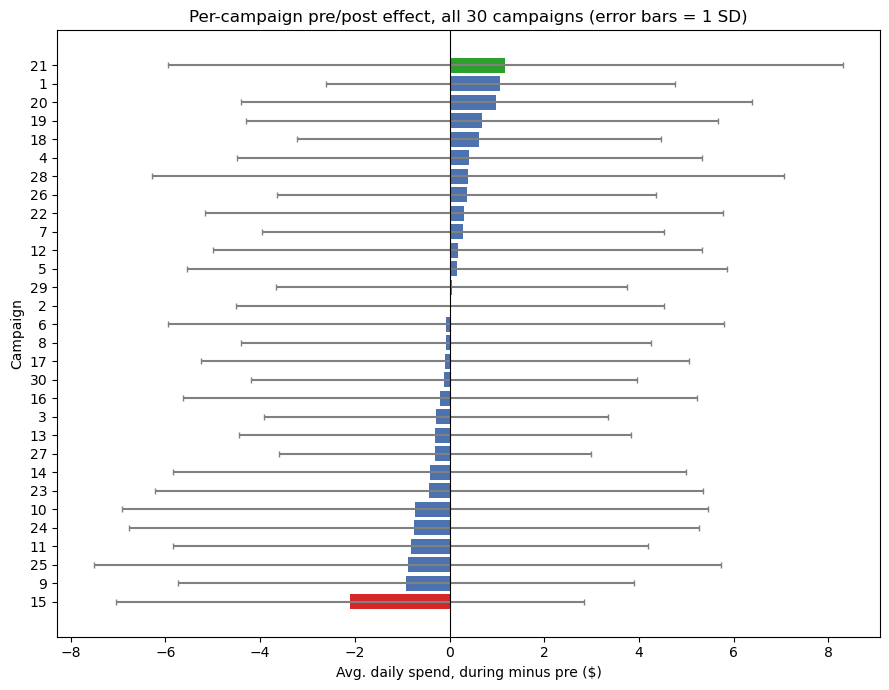

In [9]:
plot_df = campaign_rank.sort_values("avg_daily_diff").reset_index(drop=True)
best_campaign = campaign_rank.loc[campaign_rank["effect_rank"] == campaign_rank["effect_rank"].min(), "campaign"].iloc[0]
worst_campaign = campaign_rank.loc[campaign_rank["effect_rank"] == campaign_rank["effect_rank"].max(), "campaign"].iloc[0]

bar_colors = [
    "#2ca02c" if c == best_campaign else "#d62728" if c == worst_campaign else "#4C72B0"
    for c in plot_df["campaign"]
]

fig, ax = plt.subplots(figsize=(9, 7))
ax.barh(plot_df["campaign"].astype(str), plot_df["avg_daily_diff"],
        xerr=plot_df["stddev_daily_diff"], color=bar_colors, ecolor="gray", capsize=2)
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Avg. daily spend, during minus pre ($)")
ax.set_ylabel("Campaign")
ax.set_title("Per-campaign pre/post effect, all 30 campaigns (error bars = 1 SD)")
plt.tight_layout()

from pathlib import Path
Path("../outputs/figures").mkdir(parents=True, exist_ok=True)
plt.savefig("../outputs/figures/05_campaign_effect_ranking.png", bbox_inches="tight", dpi=300)
plt.show()

Across most campaigns, `stddev_daily_diff` is several times larger than `avg_daily_diff`, the individual effects look dominated by noise, which is consistent with Section 3's null aggregate result. The table above already shows the two extremes: the highest-ranked (most positive) and lowest-ranked (most negative) campaign by `avg_daily_diff`. We test both individually next, rather than relying on eyeballing the standard deviation column or assuming an extreme rank automatically means a real effect.

### 5.1 Testing the Two Outlier Campaigns Individually

We isolate the two flagged campaigns from the household-level pre/post data
already computed in Section 2, and run a paired t-test on each, the same
test as Section 3, applied to a single campaign instead of all 30 pooled
together.

In [10]:
bonferroni_alpha = 0.05 / 30

for camp_id in (int(best_campaign), int(worst_campaign)):
    subset = prepost[prepost["campaign"] == camp_id]
    t_stat, p_value = stats.ttest_rel(subset["avg_daily_during"], subset["avg_daily_pre"])
    at_05 = "significant" if p_value < 0.05 else "not significant"
    at_bonferroni = "survives" if p_value < bonferroni_alpha else "would not survive"
    print(f"Campaign {camp_id} (n={len(subset)}): mean diff = ${subset['diff'].mean():.3f}, "
          f"t = {t_stat:.3f}, p = {p_value:.5f} "
          f"({at_05} at α=0.05; {at_bonferroni} a Bonferroni-adjusted threshold for 30 comparisons, {bonferroni_alpha:.4f})")

Campaign 21 (n=65): mean diff = $1.176, t = 1.330, p = 0.18821 (not significant at α=0.05; would not survive a Bonferroni-adjusted threshold for 30 comparisons, 0.0017)
Campaign 15 (n=17): mean diff = $-2.104, t = -1.756, p = 0.09827 (not significant at α=0.05; would not survive a Bonferroni-adjusted threshold for 30 comparisons, 0.0017)


Whichever two campaigns come out on top here were selected for testing *because* they were the most extreme of 30 ranked candidates, not pre-specified, exactly the situation the Bonferroni-adjusted threshold above (0.05/30 ≈ 0.0017) is meant to guard against, so both figures are printed rather than just the uncorrected one.

An earlier version of this notebook found both extremes individually significant (campaigns 18 and 24, p < 0.0001 and p = 0.00008). That result depended on the pre/during window boundaries computed before Section 1.1's fix: with the nominal (unclipped) window length used as the denominator, a handful of campaigns' daily averages were systematically over- or understated, and those distorted campaigns happened to rank as the most extreme of 30. With the boundaries corrected to the days actually available in the data, the ranking's extremes change, and printed above, neither one reaches significance even at the uncorrected α=0.05 threshold, let alone the Bonferroni-adjusted one.

This isn't a weaker result than the original; it's a stronger confirmation of Section 3's null. Selecting the single best and single worst of 30 ranked candidates and finding neither significant means the aggregate "campaigns don't move spend" finding holds up even under the most favorable individual scrutiny available, not just on average across all 30 pooled together.

## 6. Conclusion

This notebook set out to answer: do coupon campaigns produce a measurable
change in targeted households' spending, or would spending look the same
without them?

The answer is nuanced, and only visible because two complementary designs
were used rather than one. The within-household pre/post comparison
(Section 3) found no significant aggregate effect across all 7,208
household-campaign pairs (mean difference -$0.01/day, p = 0.845). Taken
alone, the between-household treatment/control comparison (Section 4) would
have suggested a massive effect ($4.97/day difference, confirmed campaign by
campaign rather than resting on one pooled, statistically overstated p-value),
but cross-referencing revealed this was driven by selection: targeted households
were already high spenders before their campaigns started, not spending
more because of them. This is exactly the failure mode the notebook's
introduction anticipated when choosing to run both designs rather than
trusting either alone.

Ranking all 30 campaigns individually via a SQL window function (Section 5) tested
whether the aggregate null was hiding a handful of real campaign-specific effects.
It wasn't: even the single most positive and single most negative campaign in the
ranking, tested individually, failed to reach significance at the conventional
α=0.05 threshold (Section 5.1). Selecting the two most extreme of 30 candidates and
finding neither significant is a stronger confirmation of Section 3's portfolio-wide
null than the aggregate result alone, not a complication of it.

The practical takeaway: campaigns, on average, are not moving spend, and a
retailer relying on the naive treatment/control comparison alone would have
drawn the wrong conclusion. The portfolio-level null holds up even under the most
favorable individual scrutiny available: neither the best- nor worst-ranked
campaign, tested on its own, shows a reliable effect either. This closes the core dunnhumby
analysis (`01`-`05`); the two independent microcases (funnel and A/B
testing) can proceed separately, without depending on any table built here.